# ARTI5001 — Assignment 3: Single-speaker Text-to-Speech
**Group 62 | Tacotron2 + frozen HiFi-GAN | Existing runs: 1,000 and 2,000 updates**

This notebook contains the implementation, fixed data protocol, saved experimental evidence, evaluation methods and playable generated examples. Its default **Run All** path reviews existing evidence; it does **not** train, download models or generate new audio. Full training and inference functions are included behind explicit switches.

Team members / student IDs / contributions: **complete with the actual three members before submission**. Do not infer contribution allocations from this notebook.

The ZIP folder is designed to contain this notebook, `data/` and `wav_examples/`. Original LJSpeech data, virtual environments and download caches are excluded. Existing fine-tuned checkpoints remain in the project and are optional external inputs for generating new speech; configure `A3_CHECKPOINT_ROOT` on another computer. Cached examples and bundled results can be reviewed without them.

Sections: setup; data and splits; preprocessing; model/loss implementation; controlled experiments and checkpointing; results/curves; objective and human evaluation; audio diagnosis; arbitrary-text inference; conclusions and provenance.

## 1. Portable paths and safe execution
Find the notebook/submission folder from the current directory, then locate the optional full project by walking upward or setting `A3_PROJECT_ROOT`. No machine-specific drive is required. The copied Windows environment was tested at the new location; environment activation and helper-script roots are recorded separately in the migration report.

In [1]:
from pathlib import Path
import os, sys, json, csv, random, hashlib, statistics, platform, importlib.metadata
import numpy as np
from IPython.display import display, Markdown, HTML, Audio

def find_submission(start):
    start = Path(start).resolve()
    candidates = [start, *start.parents]
    for parent in candidates:
        for candidate in [parent, parent / 'submission' / '62_A3']:
            if (candidate / '62_A3.ipynb').exists() and (candidate / 'wav_examples' / 'audio_manifest.csv').is_file():
                return candidate
    raise FileNotFoundError('Open this notebook from the folder containing wav_examples/.')

SUBMISSION_ROOT = find_submission(Path.cwd())
if os.environ.get('A3_PROJECT_ROOT'):
    PROJECT_ROOT = Path(os.environ['A3_PROJECT_ROOT']).expanduser().resolve()
else:
    PROJECT_ROOT = next((p for p in [SUBMISSION_ROOT, *SUBMISSION_ROOT.parents]
                         if (p / 'LJSpeech-1.1' / 'metadata.csv').exists()), SUBMISSION_ROOT)
DATA_ROOT = Path(os.environ.get('LJSPEECH_ROOT', str(PROJECT_ROOT / 'LJSpeech-1.1')))
CHECKPOINT_ROOT = Path(os.environ.get('A3_CHECKPOINT_ROOT', str(PROJECT_ROOT / 'checkpoints')))
OUTPUT_ROOT = SUBMISSION_ROOT / 'optional_new_outputs'
RUN_TRAINING = False
RUN_NEW_INFERENCE = False
RUN_NEW_ASR = False
print('Submission:', SUBMISSION_ROOT)
print('Optional full project:', PROJECT_ROOT)
print('Training:', RUN_TRAINING, '| New inference:', RUN_NEW_INFERENCE)
# These switches are False in the distributed review notebook.


Submission: D:\Assignment\5001\a3\submission\62_A3
Optional full project: D:\Assignment\5001\a3
Training: False | New inference: False


## 2. Saved evidence and environment
`data/experiment_evidence.json` contains the fixed split lists, configurations, recorded training logs, evaluation results, audio index and human observations. Cell 5 loads it with a path relative to this submission folder. Keep `data/` beside this notebook, `data/` and `wav_examples/` when moving or extracting the ZIP. These are existing measurements, not new training results. Historical absolute paths in records are provenance, not execution paths.

In [2]:
# Saved measurements and configuration, kept separate from notebook code.
EVIDENCE_PATH = SUBMISSION_ROOT / "data" / "experiment_evidence.json"
with EVIDENCE_PATH.open(encoding="utf-8") as handle:
    EVIDENCE = json.load(handle)

assert EVIDENCE["group"] == 62
print("Evidence loaded:", EVIDENCE_PATH.relative_to(SUBMISSION_ROOT))
print("Logged updates:", {name: len(rows) for name, rows in EVIDENCE["metrics"].items()})


Evidence loaded: data\experiment_evidence.json
Logged updates: {'expA': 2000, 'expB': 2000}


In [3]:
versions = {}
for name in ['torch', 'torchaudio', 'speechbrain', 'numpy', 'soundfile', 'matplotlib']:
    try: versions[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: versions[name] = 'not installed'
print('Review Python:', platform.python_version())
print(versions)
print('Recorded training: Python 3.10.11, torch/torchaudio 2.11.0+cu128, SpeechBrain 1.0.3; RTX 5070 Ti 16GB; RAM 32GB.')
print('Install matching torch/torchaudio from https://download.pytorch.org/whl/cu128; other recorded versions are in the project requirements files.')


Review Python: 3.10.11
{'torch': '2.11.0+cu128', 'torchaudio': '2.11.0+cu128', 'speechbrain': '1.0.3', 'numpy': '2.2.6', 'soundfile': '0.14.0', 'matplotlib': '3.10.9'}
Recorded training: Python 3.10.11, torch/torchaudio 2.11.0+cu128, SpeechBrain 1.0.3; RTX 5070 Ti 16GB; RAM 32GB.
Install matching torch/torchaudio from https://download.pytorch.org/whl/cu128; other recorded versions are in the project requirements files.


## 3. Data handling and fixed splits
LJSpeech has 13,100 paired utterances. Prior full-file verification found no missing, extra, empty or truncated WAVs. Audio is mono 22,050 Hz / 16-bit PCM, approximately 23.92 hours. `metadata.csv` has three literal pipe-separated fields: ID, original transcript and normalized transcript. Treat quotes as text, not CSV quoting.

Protocol: lexicographically sort IDs, shuffle with Python `random.Random(42)`, slice 80/10/10. The saved lists are authoritative. Fine-tuning uses the **first 2,000 IDs of the saved shuffled training list**, without duration filtering; both experiments share all 1,310 validation items. The 1,310-item test split is reserved and was not evaluated in full. Validation diagnostics have been used for development and are not an independent final test.

In [4]:
def reproduce_split_ids(all_ids, seed=42):
    ids = sorted(all_ids)
    random.Random(seed).shuffle(ids)
    n = len(ids); a = int(.8*n); b = int(.1*n)
    return {'train': ids[:a], 'val': ids[a:a+b], 'test': ids[a+b:]}

def read_ljspeech_metadata(root):
    rows = [line.split('|') for line in (Path(root)/'metadata.csv').read_text(encoding='utf-8').splitlines()]
    assert all(len(row)==3 and all(v.strip() for v in row) for row in rows)
    assert len({row[0] for row in rows}) == len(rows)
    return {row[0]: {'original':row[1], 'normalized':row[2]} for row in rows}

splits = EVIDENCE['split_ids']
assert [len(splits[k]) for k in ['train','val','test']] == [10480,1310,1310]
assert all(set(splits[a]).isdisjoint(splits[b]) for a,b in [('train','val'),('train','test'),('val','test')])
assert reproduce_split_ids(set().union(*map(set,splits.values()))) == splits
assert [r['id'] for r in EVIDENCE['manifests']['train']] == splits['train'][:2000]
assert [r['id'] for r in EVIDENCE['manifests']['val']] == splits['val']
print('Saved split reproduction and non-overlap: PASS')
for split, rows in EVIDENCE['manifests'].items():
    print(split, len(rows), 'utterances;', round(sum(r['duration'] for r in rows)/3600,3),'hours')
if DATA_ROOT.exists():
    metadata = read_ljspeech_metadata(DATA_ROOT)
    missing = [uid for uid in metadata if not (DATA_ROOT/'wavs'/f'{uid}.wav').exists()]
    assert not missing
    print('Local metadata:',len(metadata),'| all audio paths exist')
else:
    print('Dataset not bundled. Download from https://keithito.com/LJ-Speech-Dataset/ and set LJSPEECH_ROOT to perform local checks/training.')


Saved split reproduction and non-overlap: PASS
train 2000 utterances; 3.686 hours
val 1310 utterances; 2.362 hours
test 1310 utterances; 2.373 hours


Local metadata: 13100 | all audio paths exist


## 4. Official preprocessing, model and loss
The version-matched SpeechBrain v1.0.3 LJSpeech/Tacotron2 recipe was inspected; 22 architecture fields matched the downloaded inference configuration. This establishes implementation/architecture compatibility, not proof of every historical pretraining setting.

Mel: 22,050 Hz, FFT/window 1024, hop 256, 80 bands, 0–8,000 Hz, magnitude power 1, no STFT magnitude normalization, Slaney normalization/scale, log compression with floor 1e-5. Use the normalized transcript (column 3), then official `english_cleaners`. No trimming or peak normalization was used in training.

The code below is the project implementation using official model, collation, mel and loss components. Its path root is adapted for this notebook; no training is invoked by defining it. The soundfile backend compatibility shim is local to this Python process. Source: [SpeechBrain v1.0.3 recipe](https://github.com/speechbrain/speechbrain/tree/v1.0.3/recipes/LJSpeech/TTS/tacotron2).

In [5]:
"""Shared preprocessing, adapted from SpeechBrain v1.0.3 LJSpeech/TTS/tacotron2.
Official reference: https://github.com/speechbrain/speechbrain/tree/v1.0.3/recipes/LJSpeech/TTS/tacotron2
"""
from pathlib import Path
import os
ROOT = PROJECT_ROOT
os.environ['HF_HOME'] = str(ROOT / 'models' / 'huggingface')
import json, hashlib, random
import numpy as np
import torch, torchaudio, soundfile as sf
if not hasattr(torchaudio, 'list_audio_backends'):
    torchaudio.list_audio_backends = lambda: ['soundfile']
from speechbrain.inference.TTS import Tacotron2
from speechbrain.inference.vocoders import HIFIGAN
from speechbrain.utils.fetching import LocalStrategy
from speechbrain.utils.text_to_sequence import text_to_sequence
from speechbrain.lobes.models.Tacotron2 import TextMelCollate, mel_spectogram, Loss

MEL = dict(sample_rate=22050, hop_length=256, win_length=1024, n_fft=1024,
           n_mels=80, f_min=0.0, f_max=8000.0, power=1, normalized=False,
           norm='slaney', mel_scale='slaney', compression=True)

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def write_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2)+'\n', encoding='utf-8')

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def load_tts(trainable=False):
    # Use existing local files; no new model download or random initialization.
    folder = ROOT/'models'/'tacotron2'
    wrapper = Tacotron2.from_hparams(source=str(folder), savedir=str(folder),
        run_opts={'device':'cuda'}, local_strategy=LocalStrategy.COPY,
        freeze_params=not trainable)
    model = wrapper.mods.model
    model.requires_grad_(trainable)
    return wrapper, model

class SpeechDataset(torch.utils.data.Dataset):
    def __init__(self, manifest):
        self.records = json.loads(Path(manifest).read_text(encoding='utf-8'))
        self.cache = {}
    def __len__(self): return len(self.records)
    def __getitem__(self, index):
        if index not in self.cache:
            r=self.records[index]
            wav=ROOT/r['wav']
            audio,sr=sf.read(str(wav),dtype='float32')
            assert sr==MEL['sample_rate'] and audio.ndim==1
            # soundfile float32 PCM conversion matches normalized float audio reading.
            mel=mel_spectogram(audio=torch.from_numpy(audio), **MEL)
            tokens=torch.IntTensor(text_to_sequence(r['label'], ['english_cleaners']))
            assert tokens.numel()>0 and tokens.max()<148 and torch.isfinite(mel).all()
            self.cache[index]={'mel_text_pair':(tokens,mel,len(tokens)),
                               'label':r['label'],'wav':str(wav)}
        return dict(self.cache[index])

def batch(dataset, indices):
    # Official collator sorts text lengths, pads mels and builds stop-gate targets.
    b=TextMelCollate(n_frames_per_step=1)([dataset[i] for i in indices])
    text,lengths,mel,gate,out_lengths=b[:5]
    text,lengths,mel,gate,out_lengths=[x.cuda() for x in (text,lengths,mel,gate,out_lengths)]
    return (text.long(),lengths.long(),mel.float(),int(lengths.max()),out_lengths.long()), (mel.float(),gate.float())

def criterion():
    # Pretrained model already has an alignment. Disable scratch-training auxiliary term.
    return Loss(guided_attention_sigma=.2, gate_loss_weight=1., guided_attention_weight=0.).cuda()

def loss_stats(model, loss_fn, packed):
    inputs,targets=packed
    prediction=model(inputs,alignments_dim=int(inputs[1].max()))
    return loss_fn(prediction,targets,inputs[1],inputs[4],1)

def synthesize(wrapper, output, text):
    folder=ROOT/'models'/'hifigan'
    vocoder=HIFIGAN.from_hparams(source=str(folder),savedir=str(folder),
        run_opts={'device':'cuda'},local_strategy=LocalStrategy.COPY)
    vocoder.eval(); vocoder.requires_grad_(False); wrapper.eval()
    with torch.inference_mode():
        mel,lengths,_=wrapper.encode_text(text)
        assert 0<int(lengths[0])<wrapper.mods.model.decoder.max_decoder_steps, 'Decoder failed to stop'
        waveform=vocoder.decode_batch(mel)
    audio=waveform.squeeze().cpu().numpy()
    assert audio.ndim==1 and np.isfinite(audio).all() and np.abs(audio).max()>0
    Path(output).parent.mkdir(parents=True,exist_ok=True)
    sf.write(str(output),audio,22050,subtype='PCM_16')
    decoded,sr=sf.read(str(output)); assert sr==22050 and len(decoded)==len(audio)
    return {'wav':str(output),'seconds':len(audio)/sr,'sample_rate':sr,
            'peak':float(np.abs(audio).max()),'finite_nonzero_audio':True,
            'tts_device':str(next(wrapper.mods.parameters()).device),
            'vocoder_device':str(next(vocoder.mods.parameters()).device)}


D:\Assignment\5001\a3\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training is teacher-forced: text IDs and the preceding target mel frame enter Tacotron2. The target mel is extracted from real audio. Total loss = decoder mel MSE + postnet mel MSE + stop-gate BCE. Guided-attention weight is zero for this fine-tuning study. HiFi-GAN is frozen and absent from the training loss. `TextMelCollate` sorts lengths, pads sequences and constructs stop targets; `batch` moves tensors to CUDA. The dataset cache is suitable for this subset but should be memory-budgeted when scaling up.

In [6]:
# A lightweight real-sample sanity check: preprocessing only, no model update.
if DATA_ROOT.exists():
    sample = EVIDENCE['manifests']['train'][0]
    audio, sr = sf.read(str(DATA_ROOT/'wavs'/f"{sample['id']}.wav"), dtype='float32')
    target_mel = mel_spectogram(audio=torch.from_numpy(audio), **MEL)
    tokens = text_to_sequence(sample['label'], ['english_cleaners'])
    assert sr == 22050 and target_mel.shape[0] == 80 and np.isfinite(target_mel.numpy()).all()
    print(sample['id'], '| tokens:',len(tokens),'| mel:',tuple(target_mel.shape))
else:
    print('Optional local audio sanity check skipped: dataset not supplied.')


LJ041-0107 | tokens: 142 | mel: (80, 720)


## 5. Inference front-end repairs and regression
The installed cleaner does not expand numbers; digits and `$` are absent from its character inventory. Explicit numeric/money expansion fixed lost quantities. Dotted-initialism expansion was then tested using one A–Z table, but user listening found **U.N. correct before expansion and wrong after**. Therefore numbers/money remain enabled while initialism expansion is **opt-in, off by default**. Neither repair was inserted into the frozen training procedure.

The following implementation is included in full. It handles supported integers, decimals and US dollar amounts, and fails explicitly for certain ambiguous formats rather than claiming universal English normalization. Dotted expansion is restricted to uppercase letter sequences; titles, lowercase Latin abbreviations, domains and undotted acronyms are not guessed.

In [7]:
"""English cardinal numbers, decimals and US dollar amounts for TTS input.

Expand before SpeechBrain english_cleaners/tokenization, which otherwise drops digits.
No package monkey-patching or model changes. This is an explicit inference front end;
ambiguous dates/times, ordinals, scientific notation and other currencies are out of scope.
"""
import re

ONES = ('zero one two three four five six seven eight nine ten eleven twelve '
        'thirteen fourteen fifteen sixteen seventeen eighteen nineteen').split()
TENS = 'zero ten twenty thirty forty fifty sixty seventy eighty ninety'.split()
SCALES = [(10**12,'trillion'),(10**9,'billion'),(10**6,'million'),(1000,'thousand')]
NUMBER = r'(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?'
MONEY_RE = re.compile(r'(?<![\w$])(?P<sign>-?)\$(?P<amount>'+NUMBER+r')(?!\w|,\d|\.\d)')
NUMBER_RE = re.compile(r'(?<![\w.])(?P<sign>-?)(?P<number>'+NUMBER+r')(?![\w]|\.\d)')

def integer_words(number):
    number=int(number)
    if number<0:return 'minus '+integer_words(-number)
    if number>=10**15:raise ValueError('Numbers of a quadrillion or greater are unsupported')
    if number<20:return ONES[number]
    if number<100:return TENS[number//10]+(' '+ONES[number%10] if number%10 else '')
    if number<1000:return ONES[number//100]+' hundred'+(' '+integer_words(number%100) if number%100 else '')
    for scale,label in SCALES:
        if number>=scale:
            return integer_words(number//scale)+' '+label+(' '+integer_words(number%scale) if number%scale else '')

def _money(match):
    value=match['amount'].replace(',','')
    whole,_,fraction=value.partition('.')
    if len(fraction)>2:raise ValueError('Dollar amounts must have at most two decimal places')
    dollars=int(whole);cents=int(fraction.ljust(2,'0') or '0')
    components=[]
    if dollars or not cents:components.append(integer_words(dollars)+(' dollar' if dollars==1 else ' dollars'))
    if cents:components.append(integer_words(cents)+(' cent' if cents==1 else ' cents'))
    return ('minus ' if match['sign'] else '')+' and '.join(components)

def _number(match):
    value=match['number'].replace(',','')
    whole,point,fraction=value.partition('.')
    # Leading-zero strings are read digit by digit (e.g. 007), not as seven.
    words=' '.join(ONES[int(c)] for c in whole) if len(whole)>1 and whole.startswith('0') else integer_words(whole)
    if point:words+=' point '+' '.join(ONES[int(c)] for c in fraction)
    return ('minus ' if match['sign'] else '')+words

def expand_numbers_and_money(text):
    """Return text with numeric content spoken explicitly; preserve other text.

    Reject unsupported leftover numeric content rather than silently losing it at
    character tokenization. This function intentionally does not guess dates/times.
    """
    if re.search(r'\d:\d|\d/\d|\d(?:st|nd|rd|th)\b|\d[eE][+-]?\d',text):
        raise ValueError('Write times, dates, ordinals or scientific notation in spoken words')
    if re.search(r'(?<!\w)\.\d',text):
        raise ValueError('Use an explicit leading zero for decimals, e.g. 0.5')
    if re.search(r'(?<!\d)\d{1,2},\d{1,2}(?!\d)',text):
        raise ValueError('Invalid thousands grouping')
    text=MONEY_RE.sub(_money,text)
    if '$' in text:raise ValueError('Unsupported dollar amount; use $12.50 or write spoken words')
    if re.search(r'[£€¥]',text):raise ValueError('Write non-USD currency amounts in spoken words')
    text=NUMBER_RE.sub(_number,text)
    if re.search(r'\d',text):raise ValueError('Unsupported numeric token; write it in spoken words')
    return text


In [8]:
"""Optional uppercase dotted initialisms via ONE A-Z letter-name table.
Default policy: preserve abbreviations; always repair supported numbers/money.
Only character inputs; does not assume ARPAbet embeddings were trained.
Lowercase e.g./i.e., titles, decimals, domains and undotted acronyms are not guessed.
"""
import re


LETTER_NAMES=dict(zip('ABCDEFGHIJKLMNOPQRSTUVWXYZ',[
    'ay','bee','see','dee','ee','ef','jee','aitch','eye','jay','kay','el','em',
    'en','oh','pee','cue','ar','ess','tee','you','vee','double you','ex','why','zee']))
DOTTED_INITIALISM=re.compile(r'(?<![A-Za-z0-9_.])(?:[A-Z]\.)+[A-Z]\.?(?![A-Za-z0-9_]|\.[A-Za-z0-9])')

def expand_dotted_initialisms(text):
    def expand(match):
        token=match.group(0)
        letters=token.replace('.','')
        return ', '.join(LETTER_NAMES[letter] for letter in letters)+('.' if token.endswith('.') else '')
    return DOTTED_INITIALISM.sub(expand,text)

def prepare_acronym_text(text, *, expand_initialisms=False):
    """Always repair numbers/money; preserve abbreviations unless explicitly enabled.

    Example: prepare_acronym_text(text, expand_initialisms=True) is an experimental
    opt-in, not a guaranteed pronunciation improvement (U.N. has a human regression).
    """
    if expand_initialisms:
        text=expand_dotted_initialisms(text)
    return expand_numbers_and_money(text)


In [9]:
assert prepare_acronym_text('U.N. has 12 reports costing $12.50.') == 'U.N. has twelve reports costing twelve dollars and fifty cents.'
assert prepare_acronym_text('U.N.', expand_initialisms=True) == 'you, en.'
assert expand_numbers_and_money('$1.01') == 'one dollar and one cent'
print('Default policy: original abbreviations preserved; numbers/money repaired. Regression checks: PASS')


Default policy: original abbreviations preserved; numbers/money repaired. Regression checks: PASS


## 6. Controlled configurations and reproducible training implementation
Only learning rate differs: A = 1e-5, B = 5e-5. Both use batch 4, Adam weight decay 6e-6, gradient clipping 1, FP32, seed 42 and full validation every 250 updates. 1,000 updates = two passes through 2,000 training examples; 2,000 = four passes. The 2k runs continue each experiment's own 1k `last.pt`, restoring Adam and Python/NumPy/CPU/GPU random states. These are two extended training trajectories, not four independent replicates.

The implementation below follows the executed trainer. Notebook-only adaptations are: configuration comes from bundled evidence and outputs go to `optional_new_outputs/`, protecting submitted evidence. The loss, optimizer, validation, ordering and checkpoint logic are retained. Review mode does not call the training function.

In [10]:
EXPERIMENT_CONFIGS = EVIDENCE['configs']
for name, config in EXPERIMENT_CONFIGS.items(): print(name, config)
a, b = EXPERIMENT_CONFIGS['expA'], EXPERIMENT_CONFIGS['expB']
assert {k for k in a if a[k] != b[k]} == {'name','learning_rate'}
print('Only experimental difference: learning_rate (name only routes outputs).')


expA {'name': 'expA', 'learning_rate': 1e-05, 'seed': 42, 'train_manifest': 'data_manifests/formal/train.json', 'val_manifest': 'data_manifests/formal/val.json', 'batch_size': 4, 'weight_decay': 6e-06, 'gradient_clip': 1.0, 'max_steps': 1000, 'validation_interval': 250, 'guided_attention_weight': 0.0, 'precision': 'float32', 'prompt': 'Hello. This is our first speech synthesis test for Assignment Three.'}
expB {'name': 'expB', 'learning_rate': 5e-05, 'seed': 42, 'train_manifest': 'data_manifests/formal/train.json', 'val_manifest': 'data_manifests/formal/val.json', 'batch_size': 4, 'weight_decay': 6e-06, 'gradient_clip': 1.0, 'max_steps': 1000, 'validation_interval': 250, 'guided_attention_weight': 0.0, 'precision': 'float32', 'prompt': 'Hello. This is our first speech synthesis test for Assignment Three.'}
Only experimental difference: learning_rate (name only routes outputs).


In [11]:
"""Small supervised fine-tuning scaffold; official SB model, collator, mel and loss.
Use --verify-only to reload the saved checkpoint in a fresh process and synthesize.
Use --resume --steps 5 to prove optimizer/RNG restoration and run one more update.
This pilot is not a complete assignment or evidence of improved speech quality.
"""

import argparse, time, csv, sys, platform

def validate(model, fn, dataset, size):
    model.eval(); totals=[]
    with torch.no_grad():
        for start in range(0,len(dataset),size):
            ids=list(range(start,min(start+size,len(dataset))))
            value=loss_stats(model,fn,batch(dataset,ids)).loss
            assert torch.isfinite(value)
            totals.append((float(value),len(ids)))
    return sum(v*n for v,n in totals)/sum(n for _,n in totals)

def training_entrypoint():
    p=argparse.ArgumentParser()
    p.add_argument('--experiment',choices=['expA','expB'],required=True)
    p.add_argument('--steps',type=int)
    p.add_argument('--resume',action='store_true')
    p.add_argument('--verify-only',action='store_true')
    args=p.parse_args()
    c=dict(EXPERIMENT_CONFIGS[args.experiment])
    assert c['precision']=='float32' and c['guided_attention_weight']==0
    assert torch.cuda.is_available()
    seed_all(c['seed']); torch.cuda.reset_peak_memory_stats()
    directory=OUTPUT_ROOT/c['name']/'checkpoints'; directory.mkdir(parents=True,exist_ok=True)
    checkpoint=directory/'last.pt'
    manifests={key:sha(ROOT/c[key]) for key in ('train_manifest','val_manifest')}
    wrapper,model=load_tts(trainable=True)
    optimizer=torch.optim.Adam(model.parameters(),lr=c['learning_rate'],weight_decay=c['weight_decay'])
    fn=criterion()
    start_step=0; best=float('inf'); restored=False
    if args.resume or args.verify_only:
        # This is a locally produced trusted checkpoint containing optimizer/RNG state.
        state=torch.load(checkpoint,map_location='cpu',weights_only=False)
        assert state['manifest_hashes']==manifests, 'Data manifests changed'
        assert state['config']==c, 'Config changed; start a new experiment instead'
        model.load_state_dict(state['model'],strict=True)
        assert all(torch.equal(v.detach().cpu(),state['model'][k]) for k,v in model.state_dict().items())
        optimizer.load_state_dict(state['optimizer'])
        start_step=state['step']; best=state['best_validation']; restored=True
        random.setstate(state['rng_python']); np.random.set_state(state['rng_numpy'])
        torch.set_rng_state(state['rng_torch']); torch.cuda.set_rng_state_all(state['rng_cuda'])
        print(f'Restored all model tensors and Adam state at step {start_step}',flush=True)
        del state
    elif checkpoint.exists():
        raise RuntimeError('Pilot checkpoint exists. Use --resume or choose a new config/name.')

    if args.verify_only:
        model.eval()
        audio=synthesize(wrapper,ROOT/'wav_examples'/f'{c["name"]}_reloaded_step{start_step}.wav',c['prompt'])
        write_json(ROOT/'logs'/c['name']/'reload_verification.json',
            {'checkpoint':str(checkpoint),'checkpoint_sha256':sha(checkpoint),'step':start_step,
             'all_model_tensors_match_checkpoint':True,'optimizer_state_loaded':restored,
             'fresh_process':True,**audio})
        print(json.dumps(audio,indent=2),flush=True)
        return

    training=SpeechDataset(ROOT/c['train_manifest']); validation=SpeechDataset(ROOT/c['val_manifest'])
    assert len(training)>=c['batch_size']
    before=model.embedding.weight.detach().clone()
    rng_cpu=torch.get_rng_state(); rng_gpu=torch.cuda.get_rng_state_all()
    initial_validation=validate(model,fn,validation,c['batch_size'])
    # Validation uses stochastic prenet dropout. Preserve training RNG around baseline
    # measurement so a resumed run continues from the saved random state.
    torch.set_rng_state(rng_cpu); torch.cuda.set_rng_state_all(rng_gpu)
    max_steps=args.steps if args.steps is not None else c['max_steps']
    assert max_steps>start_step
    logdir=OUTPUT_ROOT/c['name']/'logs';logdir.mkdir(parents=True,exist_ok=True)
    write_json(logdir/'config.json',c)
    metrics=logdir/'metrics.csv'
    if start_step==0:
        metrics.write_text('step,train_loss,mel_loss,gate_loss,gradient_norm,validation_loss,elapsed_seconds\n',encoding='utf-8')
    batches_per_epoch=len(training)//c['batch_size']
    start=time.perf_counter(); final_val=initial_validation
    for step in range(start_step,max_steps):
        epoch,offset=divmod(step,batches_per_epoch)
        order=list(range(len(training)));random.Random(c['seed']+epoch).shuffle(order)
        ids=order[offset*c['batch_size']:(offset+1)*c['batch_size']]
        model.train();optimizer.zero_grad(set_to_none=True)
        stats=loss_stats(model,fn,batch(training,ids))
        assert torch.isfinite(stats.loss), 'Nonfinite training loss'
        stats.loss.backward()
        grad=torch.nn.utils.clip_grad_norm_(model.parameters(),c['gradient_clip'],error_if_nonfinite=True)
        assert float(grad)>0
        optimizer.step()
        values=[step+1,float(stats.loss.detach()),float(stats.mel_loss.detach()),float(stats.gate_loss.detach()),float(grad),'',time.perf_counter()-start]
        if (step+1)%c['validation_interval']==0 or step+1==max_steps:
            final_val=validate(model,fn,validation,c['batch_size']);values[5]=final_val
            is_best=final_val<best; best=min(best,final_val)
            payload={'model':model.state_dict(),'optimizer':optimizer.state_dict(),'step':step+1,
                     'best_validation':best,'config':c,'manifest_hashes':manifests,
                     'rng_python':random.getstate(),'rng_numpy':np.random.get_state(),
                     'rng_torch':torch.get_rng_state(),'rng_cuda':torch.cuda.get_rng_state_all()}
            temporary=directory/'last.tmp';torch.save(payload,temporary);temporary.replace(checkpoint)
            if is_best:
                import shutil
                shutil.copy2(checkpoint,directory/'best.pt')
        with metrics.open('a',encoding='utf-8',newline='') as f:csv.writer(f).writerow(values)
        print(f'Step {step+1}/{max_steps}: loss={values[1]:.4f}, grad={values[4]:.4f}, val={values[5]}',flush=True)
    change=float((model.embedding.weight.detach()-before).abs().max())
    assert change>0, 'Weights did not update'
    report={'status':'training_checkpoint_saved','start_step':start_step,'end_step':max_steps,
        'resumed_optimizer':restored,'embedding_max_abs_change':change,
        'initial_validation_loss':initial_validation,'final_validation_loss':final_val,
        'peak_gpu_memory_mib':torch.cuda.max_memory_allocated()/2**20,'seconds':time.perf_counter()-start,
        'device':torch.cuda.get_device_name(0),'python':platform.python_version(),'torch':torch.__version__,
        'checkpoint':str(checkpoint),'manifest_hashes':manifests,
        'warning':'Optional reproduction run; no quality claim based solely on training loss.'}
    write_json(logdir/('resume_training_report.json' if restored else 'training_report.json'),report)
    print(json.dumps(report,indent=2),flush=True)




In [12]:
def materialize_embedded_manifests_for_reproduction():
    """Only called by the explicit training branch; does not overwrite project manifests."""
    destination = OUTPUT_ROOT/'data_manifests'
    destination.mkdir(parents=True, exist_ok=True)
    for split, records in EVIDENCE['manifests'].items():
        target = destination/f'{split}.json'
        text = json.dumps(records, ensure_ascii=False, indent=2)+'\n'
        if target.exists():
            assert json.loads(target.read_text(encoding='utf-8')) == records
        else: target.write_text(text, encoding='utf-8')
    for config in EXPERIMENT_CONFIGS.values():
        config['train_manifest'] = str(destination/'train.json')
        config['val_manifest'] = str(destination/'val.json')

def reproduce_training(experiment, total_steps=1000, resume=False):
    if not torch.cuda.is_available(): raise RuntimeError('The recorded trainer requires CUDA.')
    if DATA_ROOT.resolve() != (PROJECT_ROOT/'LJSpeech-1.1').resolve():
        raise RuntimeError('For exact trainer reproduction, place dataset under PROJECT_ROOT/LJSpeech-1.1.')
    materialize_embedded_manifests_for_reproduction()
    old_argv = sys.argv[:]
    try:
        sys.argv = ['notebook-training','--experiment',experiment,'--steps',str(total_steps)] + (['--resume'] if resume else [])
        training_entrypoint()
    finally: sys.argv = old_argv

if RUN_TRAINING:
    reproduce_training('expA',1000)
    reproduce_training('expB',1000)
    reproduce_training('expA',2000,resume=True)
    reproduce_training('expB',2000,resume=True)
else:
    print('Training intentionally disabled. Existing checkpoints/results are not overwritten.')


Training intentionally disabled. Existing checkpoints/results are not overwritten.


Checkpoint payloads contain model state, Adam state, step, best validation value, configuration, data hashes and random states. `last.pt` represents the endpoint; `best.pt` is selected by lowest validation loss among measured saving points. Resume validates configuration and manifest hashes. Baseline validation preserves training RNG around its measurement. Training order is deterministically reconstructed from seed + epoch and step offset.

The original source hashes and checkpoint inventory below refer to the **executed project**, not the notebook's output-routing adaptations. The historical pilot-warning string in some logs is an inherited label; the actual formal runs are 2,000 train / 1,310 validation items, 1k then 2k updates.

In [13]:
print('Executed source hashes:')
display(EVIDENCE['source_hashes'])
print('Recorded checkpoint inventory (existence optional for review):')
for item in EVIDENCE['checkpoints']:
    current = PROJECT_ROOT/item['relative_path']
    print(item['relative_path'], '| present:', current.exists(), '| SHA256:', item['sha256'])


Executed source hashes:


{'scripts/tts_training_common.py': '8b26dd82c0ef1cc5475698e78a3f96b992c76677027f3ef441b2b59c712251d9',
 'scripts/train_tacotron2.py': '6cb8f0e6a12a52821545fde70f7802fe9c2edba79e0eac2dee0799f8a17dd0ec',
 'scripts/train_tacotron2_stage2k.py': '82d62a11bd2094c75296c78c8b1e1521c603a6dbbed1972bf68c226e409bd131',
 'scripts/tts_text_preprocessing.py': '45dc1ca08fda06425163b193cc900c72b52830476c9614ed4d4a1560e19035e4',
 'scripts/tts_acronym_preprocessing.py': '7db7337cc34d252f9d3dc97e45a6a502480f63be391d50089a570e3c52488311'}

Recorded checkpoint inventory (existence optional for review):
checkpoints/expA/best.pt | present: True | SHA256: e1fb21d01b489a075a98247acd482e9fca82522748d3aa2c0b76a55df9cd3082
checkpoints/expA/last.pt | present: True | SHA256: e1fb21d01b489a075a98247acd482e9fca82522748d3aa2c0b76a55df9cd3082
checkpoints/expA/stage_2k/best.pt | present: True | SHA256: 60a3e8422f406de75e407c67841af177bc2f16bafdb2adceccde381d1f3b509a
checkpoints/expA/stage_2k/last.pt | present: True | SHA256: 168e8936d68c6da2b4e4781376484e09d93e204d13fc5c537c4432cc868084a2
checkpoints/expB/best.pt | present: True | SHA256: b9593cd69c0a46a28b11926563583fafe69f8f7a1e5c6634551d8ab15690c8e9
checkpoints/expB/last.pt | present: True | SHA256: b9593cd69c0a46a28b11926563583fafe69f8f7a1e5c6634551d8ab15690c8e9
checkpoints/expB/stage_2k/best.pt | present: True | SHA256: b9593cd69c0a46a28b11926563583fafe69f8f7a1e5c6634551d8ab15690c8e9
checkpoints/expB/stage_2k/last.pt | present: True | SHA256: bdb3919ce5ffde6525b04bd9bd2a36ad9aad63

## 7. Recorded 1k / 2k results
The following table compares **exact endpoints**, not a cherry-picked checkpoint mislabeled as 2k. True-mel reference clips are a diagnostic validation subset (148 words); custom prompts have 120 words. Do not merge these into one headline accuracy.

In [14]:
def html_table(headers, rows):
    import html
    return HTML('<table><thead><tr>'+''.join('<th>'+html.escape(str(x))+'</th>' for x in headers)+'</tr></thead><tbody>'+''.join('<tr>'+''.join('<td>'+html.escape(str(x))+'</td>' for x in row)+'</tr>' for row in rows)+'</tbody></table>')

table_rows=[]
for name in ['expA','expB']:
    audit=EVIDENCE['comparison']['audits'][name]
    for step in [1000,2000]:
        variant=f'{name}_{step//1000}k'
        loss=next(v['loss'] for v in audit['validation'] if v['step']==step)
        ref=EVIDENCE['comparison']['summary']['reference'][variant]
        custom=EVIDENCE['comparison']['summary']['custom'][variant]
        table_rows.append([name,EXPERIMENT_CONFIGS[name]['learning_rate'],step,f'{loss:.6f}',
                           f"{ref['micro_wer']:.2%} ({ref['word_errors']}/148)",
                           f"{custom['micro_wer']:.2%} ({custom['word_errors']}/120)",
                           f"{ref['aggregate_rtf']:.5f}",f"{custom['aggregate_rtf']:.5f}"])
display(html_table(['Experiment','LR','Step','Validation loss','Reference WER','Custom WER','Reference RTF','Custom RTF'],table_rows))
display(html_table(['Experiment','Best step within 2k','Best validation loss'],
    [[name,a['best_step_within_2k'],f"{a['best_loss_within_2k']:.6f}"] for name,a in EVIDENCE['comparison']['audits'].items()]))


Experiment,LR,Step,Validation loss,Reference WER,Custom WER,Reference RTF,Custom RTF
expA,1e-05,1000,0.373902,4.73% (7/148),5.83% (7/120),0.06148,0.06213
expA,1e-05,2000,0.373427,4.73% (7/148),5.00% (6/120),0.05602,0.06443
expB,5e-05,1000,0.383728,4.73% (7/148),5.00% (6/120),0.06413,0.06909
expB,5e-05,2000,0.387289,5.41% (8/148),5.83% (7/120),0.05822,0.06423


Experiment,Best step within 2k,Best validation loss
expA,1750,0.372760
expB,1000,0.383728


## 8. Training and validation curves
Raw batch losses and a trailing 50-step mean are both shown. Different batch difficulty causes substantial raw variation. The vertical line marks the continuation boundary. Validation uses all 1,310 items; stars identify the lowest measured value within 2k. The validation axis is magnified and is not a percentage.

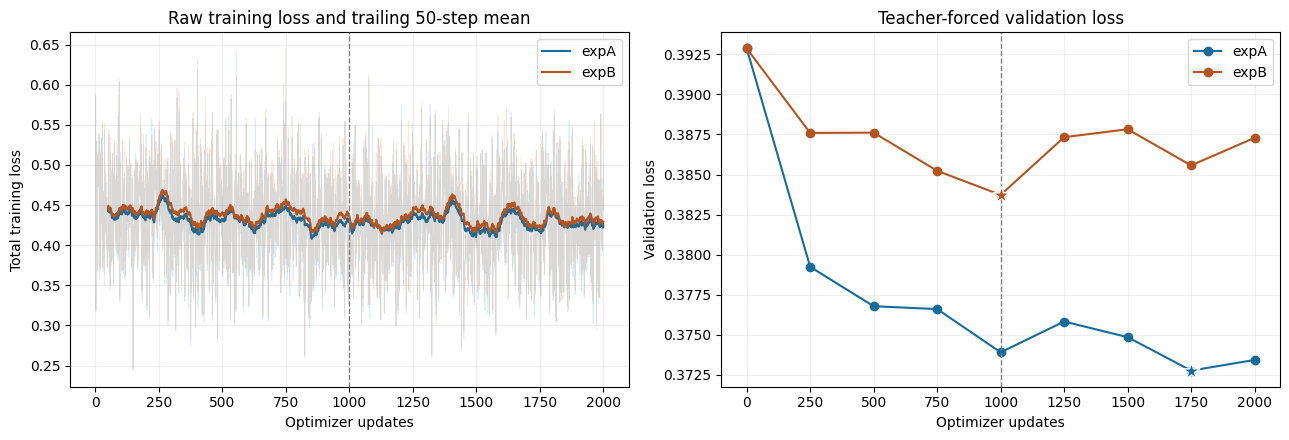

In [15]:
import matplotlib.pyplot as plt
colors={'expA':'#166d9c','expB':'#b45521'}
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name,rows in EVIDENCE['metrics'].items():
    steps=np.array([r['step'] for r in rows]);loss=np.array([r['train_loss'] for r in rows])
    axes[0].plot(steps,loss,color=colors[name],alpha=.13,lw=.6)
    axes[0].plot(steps[49:],np.convolve(loss,np.ones(50)/50,mode='valid'),color=colors[name],label=name)
    validation=EVIDENCE['comparison']['audits'][name]['validation']
    axes[1].plot([0]+[v['step'] for v in validation],[.3928682383235174]+[v['loss'] for v in validation],'-o',color=colors[name],label=name)
    best=EVIDENCE['comparison']['audits'][name]
    axes[1].scatter(best['best_step_within_2k'],best['best_loss_within_2k'],marker='*',s=160,color=colors[name],edgecolor='white',zorder=5)
for ax in axes:
    ax.axvline(1000,color='grey',ls='--',lw=1);ax.set_xlabel('Optimizer updates');ax.grid(alpha=.2);ax.legend()
axes[0].set(title='Raw training loss and trailing 50-step mean',ylabel='Total training loss')
axes[1].set(title='Teacher-forced validation loss',ylabel='Validation loss')
fig.tight_layout();plt.show()


## 9. Objective evaluation implementation and measurement protocol
Latency measures text-to-waveform inference with CUDA synchronization; RTF = synthesis seconds / output seconds. One warm-up per model is excluded; each prompt is repeated three times. Model loading and file saving are outside the timed interval. Output length changes affect RTF, and sequential system load can affect timing; small differences are not conclusive.

Local wav2vec2 ASR is a supplementary intelligibility proxy, not a naturalness score. The word-level edit distance below is used with lowercase, punctuation-stripped reference tokens. Word-boundary, spelling and recognizer errors can inflate WER; human feedback is stored separately.

In [16]:
import re, time
def word_tokens(text): return re.findall(r"[a-z]+(?:'[a-z]+)?",text.lower())
def word_edit_distance(reference,hypothesis):
    previous=list(range(len(hypothesis)+1))
    for i,x in enumerate(reference,1):
        current=[i]
        for j,y in enumerate(hypothesis,1):
            current.append(min(previous[j]+1,current[-1]+1,previous[j-1]+(x!=y)))
        previous=current
    return previous[-1]

def timed_synthesis(tts,vocoder,text,repeats=3):
    times=[];audio=None
    for _ in range(repeats):
        seed_all(42)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start=time.perf_counter()
        with torch.inference_mode():
            mel,lengths,_=tts.encode_text(text)
            waveform=vocoder.decode_batch(mel)
        if torch.cuda.is_available(): torch.cuda.synchronize()
        times.append(time.perf_counter()-start)
        if audio is None: audio=waveform.squeeze().detach().cpu().numpy()
    duration=len(audio)/22050
    return audio,{'latencies':times,'mean_latency':statistics.mean(times),
                  'stdev_latency':statistics.stdev(times),'rtf':statistics.mean(times)/duration}

def transcribe_local_wav(path,recognizer,bundle,labels,device):
    audio,sr=sf.read(str(path),dtype='float32')
    signal=torchaudio.functional.resample(torch.from_numpy(audio),sr,bundle.sample_rate).unsqueeze(0).to(device)
    with torch.inference_mode(): emission,_=recognizer(signal)
    ids=torch.unique_consecutive(emission[0].argmax(-1)).tolist()
    return ''.join(labels[i] for i in ids if i!=0).replace('|',' ').strip()

assert word_edit_distance(['a','b'],['a','c'])==1
print('Evaluation functions defined. Existing measurements below are loaded, not recomputed.')
for section in ['reference','custom']:
    print(section)
    display(html_table(['Version','Word errors','WER'],[[v,f"{s['word_errors']}/{s['reference_words']}",f"{s['micro_wer']:.2%}"]
        for v,s in EVIDENCE['comparison']['summary'][section].items()]))


Evaluation functions defined. Existing measurements below are loaded, not recomputed.
reference


Version,Word errors,WER
pretrained,7/148,4.73%
expA_1k,7/148,4.73%
expA_2k,7/148,4.73%
expB_1k,7/148,4.73%
expB_2k,8/148,5.41%


custom


Version,Word errors,WER
pretrained,7/120,5.83%
expA_1k,7/120,5.83%
expA_2k,6/120,5.00%
expB_1k,6/120,5.00%
expB_2k,7/120,5.83%


## 10. Fixed audio examples and five-way diagnosis
Ten validation items were selected before synthesis using seed 42: three <4 seconds, four 4–7 seconds and three ≥7 seconds. The five paths are real WAV, real-mel reconstruction, pretrained Tacotron2, A and B. No samples were replaced after hearing outputs.

Original dataset WAVs are **not included** in this submission. Their IDs/text and diagnostic results are retained; listen to raw references from a locally downloaded LJSpeech copy. All bundled WAVs are generated/reconstructed outputs. The code resolves local source recordings when requested, while default outputs play generated examples only. No output-level loudness normalization is applied.

In [17]:
display(html_table(['ID','LJSpeech ID','Length group','Seconds','Text'],
    [[r['display_id'],r['id'],r['length_group'],f"{r['duration']:.2f}",r['label']] for r in EVIDENCE['diagnostic']['selection']]))

def play_generated(section,sample_id,variant):
    row=next(r for r in EVIDENCE['audio_manifest'] if r['section']==section and r['id']==sample_id and r['variant']==variant)
    path=SUBMISSION_ROOT/row['submission_wav']
    assert path.exists()
    display(Markdown(f"**{section} {sample_id} — {variant}**: {row['text']}"))
    display(Audio(filename=str(path),normalize=False))

def play_local_reference(sample_id):
    row=next(r for r in EVIDENCE['diagnostic']['selection'] if r['display_id']==sample_id)
    path=DATA_ROOT/'wavs'/f"{row['id']}.wav"
    if not path.exists(): raise FileNotFoundError('Download LJSpeech locally; original recordings are not packaged.')
    display(Audio(filename=str(path),normalize=False))

# Ten cached playable generated examples; all 110 files are indexed below.
for sample_id in ['06','07']:
    for variant in ['pretrained','expA_1k','expA_2k','expB_1k','expB_2k']:
        play_generated('custom',sample_id,variant)


ID,LJSpeech ID,Length group,Seconds,Text
R01,LJ040-0096,short,1.27,"Pic said, quote,"
R02,LJ008-0218,short,3.11,They were mainly members of the criminal classes.
R03,LJ004-0160,short,3.44,"the uproar of oaths, complaints, and obscenity,"
R04,LJ025-0124,medium,4.56,"but in the plants the act of contraction has been found to be accompanied,"
R05,LJ019-0232,medium,4.60,"During this reconstruction the female prisoners were lodged in Holloway,"
R06,LJ013-0178,medium,5.53,Further suspicion was caused by the position of a book and a wax candle by the bedside.
R07,LJ021-0068,medium,6.33,to a level of sustained profits within one year from the inauguration of N.R.A.
R08,LJ009-0214,long,7.83,"and was accompanied throughout by ""an immense concourse of persons, eager to get a sight of the murderer's remains."
R09,LJ008-0095,long,9.00,"It was said that so large a crowd had never collected since the execution of Mrs. Brownrigg, nor had the public indignation risen so high."
R10,LJ049-0192,long,9.52,It was also suggested that it would take a substantial period of time for the Secret Service to build up the experience and skills necessary to meet the problem.


**custom 06 — pretrained**: There are 12 books on the shelf and 3 pencils on the desk.

**custom 06 — expA_1k**: There are 12 books on the shelf and 3 pencils on the desk.

**custom 06 — expA_2k**: There are 12 books on the shelf and 3 pencils on the desk.

**custom 06 — expB_1k**: There are 12 books on the shelf and 3 pencils on the desk.

...

**custom 07 — pretrained**: The ticket costs $12.50, including the booking fee.

**custom 07 — expA_1k**: The ticket costs $12.50, including the booking fee.

**custom 07 — expA_2k**: The ticket costs $12.50, including the booking fee.

**custom 07 — expB_1k**: The ticket costs $12.50, including the booking fee.

**custom 07 — expB_2k**: The ticket costs $12.50, including the booking fee.

In [18]:
# Compact index of every bundled example (real reference recordings deliberately excluded).
display(html_table(['Section','ID','Version','Generated WAV'],
    [[r['section'],r['id'],r['variant'],r['submission_wav']] for r in EVIDENCE['audio_manifest']]))
print('Five-way diagnostic ASR (148 reference words):')
display(html_table(['Path','Errors','WER'],[[v,s['word_errors'],f"{s['micro_wer']:.2%}"] for v,s in EVIDENCE['diagnostic']['reference_summary'].items()]))


Section,ID,Version,Generated WAV
reference,R01,reconstructed,wav_examples/reference_R01_reconstructed.wav
reference,R02,reconstructed,wav_examples/reference_R02_reconstructed.wav
reference,R03,reconstructed,wav_examples/reference_R03_reconstructed.wav
reference,R04,reconstructed,wav_examples/reference_R04_reconstructed.wav
reference,R05,reconstructed,wav_examples/reference_R05_reconstructed.wav
reference,R06,reconstructed,wav_examples/reference_R06_reconstructed.wav
reference,R07,reconstructed,wav_examples/reference_R07_reconstructed.wav
reference,R08,reconstructed,wav_examples/reference_R08_reconstructed.wav
reference,R09,reconstructed,wav_examples/reference_R09_reconstructed.wav
reference,R10,reconstructed,wav_examples/reference_R10_reconstructed.wav


Five-way diagnostic ASR (148 reference words):


Path,Errors,WER
real,2,1.35%
reconstructed,4,2.70%
pretrained,7,4.73%
expA,7,4.73%
expB,7,4.73%


## 11. Error analysis and actual human observations
- Numeric/money content was silently lost by the unmodified frontend. Explicit expansion repaired `12`, `3`, `$12.50` for all models, separating a frontend repair from learning-rate effects.
- R07 `N.R.A.` was recognizable in real/reconstructed audio but unstable in text-generated output. A letter-name repair with pauses helped that case; a no-pause trial was not stable.
- General dotted expansion had successes and failures. **U.N. was manually judged correct before processing and wrong after**; ASR non-match therefore cannot be equated with a true pronunciation error. Default expansion was disabled.
- A/B gave mixed local changes: improved recognition on some phrases, regressions on others. Human listening found real-mel reconstruction close to real recordings, supporting investigation of text/acoustic prediction before assuming the vocoder is the principal bottleneck. This is a diagnostic inference, not proof of a single cause.
- After 2k, the user reported no obvious improvement and some regression. No model/sample locations or numerical ratings were supplied, so none are invented.

These are one user's qualitative observations, not a three-rater MOS study. Final contributor review should retain this distinction.

In [19]:
for observation in EVIDENCE['human']['observations']:
    display(Markdown('**'+observation['id']+'**'))
    print(observation.get('user_statement',''))
    print('Scope:',observation.get('scope',observation.get('model_scope','')))
    print('Numeric score:',observation.get('numeric_score'))
print('Historical dotted-expansion ASR screening, not human pass rates:')
display(EVIDENCE['acronyms']['summary_matches_out_of_8'])


**human_UN_regression_20261027**

U.N.根据我的人工核实，处理前反而是对的，处理后就错了
Scope: Not specified by user; do not treat as three independent model ratings.
Numeric score: None


**human_overall_three_models_20261027**

认为这几个模型所生成的句子没有很明显的差异，并且质量都一般。
Scope: 30 generated utterances from 10 custom prompts and three models
Numeric score: None


**human_reconstruction_close_20261027**

比较接近，只是略有差别
Scope: Real-mel reconstruction versus real recordings, focusing on R02/R06/R10
Numeric score: None


**human_1k_vs_2k_no_clear_gain_20261028**

人工试听后，发现并没有明显进步，有些地方反而有退化。
Scope: Overall feedback on the 1k/2k comparison; specific sample/model locations were not provided.
Numeric score: None
Historical dotted-expansion ASR screening, not human pass rates:


{'pretrained': {'before': 0, 'after': 5},
 'expA': {'before': 0, 'after': 6},
 'expB': {'before': 1, 'after': 4}}

## 12. Arbitrary-text inference implementation (optional; off by default)
The original pretrained model can be obtained from the official repositories if explicitly requested. Existing fine-tuned inference requires the corresponding project checkpoint, or `A3_CHECKPOINT_ROOT` pointing to it. The notebook does not claim that the fine-tuned weights are embedded. Missing weights never trigger training.

Model keys: pretrained; expA_1k; expA_2k (exact 2k endpoint); expB_1k; expB_2k; expA_best (1,750 steps); expB_best (1,000 steps). Numeric repair is on and dotted expansion off unless explicitly enabled.

In [20]:
MODEL_CHECKPOINTS = {
    'expA_1k':('expA/last.pt',1000), 'expA_2k':('expA/stage_2k/last.pt',2000),
    'expB_1k':('expB/last.pt',1000), 'expB_2k':('expB/stage_2k/last.pt',2000),
    'expA_best':('expA/stage_2k/best.pt',1750), 'expB_best':('expB/stage_2k/best.pt',1000)}

def load_inference_system(model_key='pretrained',device=None):
    device=device or ('cuda' if torch.cuda.is_available() else 'cpu')
    tts_folder=PROJECT_ROOT/'models/tacotron2'
    voc_folder=PROJECT_ROOT/'models/hifigan'
    tts_source=str(tts_folder) if (tts_folder/'model.ckpt').exists() else 'speechbrain/tts-tacotron2-ljspeech'
    voc_source=str(voc_folder) if (voc_folder/'generator.ckpt').exists() else 'speechbrain/tts-hifigan-ljspeech'
    if model_key!='pretrained':
        if model_key not in MODEL_CHECKPOINTS: raise ValueError(model_key)
        path=CHECKPOINT_ROOT/MODEL_CHECKPOINTS[model_key][0]
        if not path.exists(): raise FileNotFoundError(f'Set A3_CHECKPOINT_ROOT to preserved project checkpoints: {path}')
    tts=Tacotron2.from_hparams(source=tts_source,savedir=str(tts_folder),run_opts={'device':device},local_strategy=LocalStrategy.COPY)
    voc=HIFIGAN.from_hparams(source=voc_source,savedir=str(voc_folder),run_opts={'device':device},local_strategy=LocalStrategy.COPY)
    if model_key!='pretrained':
        state=torch.load(path,map_location='cpu',weights_only=False)  # only locally produced, trusted checkpoints
        assert state['step']==MODEL_CHECKPOINTS[model_key][1]
        tts.mods.model.load_state_dict(state['model'],strict=True)
    tts.eval();voc.eval();tts.requires_grad_(False);voc.requires_grad_(False)
    return tts,voc

def generate_arbitrary_text(text,model_key='pretrained',expand_initialisms=False):
    processed=prepare_acronym_text(text,expand_initialisms=expand_initialisms)
    tts,voc=load_inference_system(model_key)
    audio,measurement=timed_synthesis(tts,voc,processed,repeats=3)
    assert np.isfinite(audio).all() and np.abs(audio).max()>0
    destination=OUTPUT_ROOT/'wavs'/f'{model_key}_new.wav'
    destination.parent.mkdir(parents=True,exist_ok=True)
    sf.write(str(destination),audio,22050,subtype='PCM_16')
    print('Input:',processed,'| measurements:',measurement)
    display(Audio(filename=str(destination),normalize=False))
    return destination

if RUN_NEW_INFERENCE:
    generate_arbitrary_text('There are 12 books, and the ticket costs $12.50.',model_key='expA_1k')
else:
    print('New model loading/download/synthesis disabled. Cached generated examples above remain playable.')


New model loading/download/synthesis disabled. Cached generated examples above remain playable.


## 13. Conclusions and limitations
Within this specific dataset subset, pretrained system and single-seed budget, extending from 1k to 2k did not yield a consistent perceptible improvement. A's exact endpoint validation loss changed only slightly (0.373902 → 0.373427); its lowest value was at 1,750. B worsened (0.383728 → 0.387289), and its validation-selected checkpoint stayed at 1k. Small ASR differences do not establish a naturalness advantage. The user chose to stop additional training.

Original pretrained speech and A1k remain reasonable practical candidates; A1750 is the validation-loss optimum, not a verified listening winner. Scaling/deployment considerations include cached weights, hardware-dependent latency, bounded sentence length, explicit text normalization and failure reporting. Additional work could include larger predeclared evaluation sets, independent raters, reliable pronunciation modeling and multiple training seeds; these were not performed here.

The primary dataset was also used for pretraining, so present splits do not establish unseen pretraining generalization. Validation diagnostics informed development. The full reserved test split was not evaluated. Original data/outputs are preserved in the project; this notebook distinguishes measured evidence from optional reproducibility code.

## 14. Attribution, team review and AI disclosure
External components: [LJSpeech](https://keithito.com/LJ-Speech-Dataset/); [SpeechBrain v1.0.3 recipe](https://github.com/speechbrain/speechbrain/tree/v1.0.3/recipes/LJSpeech/TTS/tacotron2); [Tacotron2 checkpoint](https://huggingface.co/speechbrain/tts-tacotron2-ljspeech); [HiFi-GAN checkpoint](https://huggingface.co/speechbrain/tts-hifigan-ljspeech); local torchaudio WAV2VEC2_ASR_BASE_960H. Source code retains relevant in-code links. Add the course-required Harvard bibliography in the report using sources actually consulted.

**AI assistance used in this project:** requirement clarification, planning, environment setup, code scaffolding/debugging, experiment execution support, result organization, visualization and notebook assembly. Human listening observations were supplied by the user. The team must review and understand all code, verify results, complete actual member contributions and ensure its disclosure/submission follows the course policy. No human scores, citations consulted by the team, or member contributions are invented here.

This technical notebook does not replace the separately required report PDF and presentation PPTX.

In [21]:
# Read-only submission checks. No optimizer is created or stepped by this check.
assert EVIDENCE['group']==62
assert len(EVIDENCE['audio_manifest'])==110
missing=[r['submission_wav'] for r in EVIDENCE['audio_manifest'] if not (SUBMISSION_ROOT/r['submission_wav']).exists()]
assert not missing
assert all(hashlib.sha256((SUBMISSION_ROOT/r['submission_wav']).read_bytes()).hexdigest()==r['sha256'] for r in EVIDENCE['audio_manifest'])
if not (RUN_TRAINING or RUN_NEW_INFERENCE or RUN_NEW_ASR):
    print('PASS: 110 generated WAVs, saved evidence, group 62 and review-only switches verified.')
else:
    print('Optional reproduction mode was explicitly enabled; original evidence remains separate.')
print('Training was not run. Original LJSpeech recordings and environments are not bundled.')


PASS: 110 generated WAVs, saved evidence, group 62 and review-only switches verified.
Training was not run. Original LJSpeech recordings and environments are not bundled.
